# Fase 5 — Visualización de resultados NER clínico

Este notebook descubre automáticamente los artefactos generados por `scripts/04_evaluate_ner.py` en `results/*/04_eval_summary.json` y `results/*/04_bootstrap.json`, y construye las tablas y figuras comparativas para la tesis.

**Diseño experimental:** 3 escenarios (`Baseline (0%)`, `Mixto (50%)`, `Full (100%)`) × 2 modelos (`BETO`, `XLM-R`). El archivo `test.jsonl` (SPACCC_MEDDOCAN original, 250 documentos, 5.661 entidades) es idéntico en los tres escenarios.

**Requisito:** haber ejecutado la Fase 4 para cada modelo entrenado. Ejemplo:

```bash
python scripts/04_evaluate_ner.py \
    --model-dir models/beto_full \
    --data-dir data/augmented_100 \
    --output-dir results/beto_full__augmented_100 \
    --bootstrap 1000
```

**Artefactos exportados en `results/`:**
- `05_resultados_comparativos.csv`: métricas completas por corrida.
- `05_tabla_resultados.tex`: tabla plana para tesis (Micro-F1, IC95 micro, Macro-F1, IC95 macro, Weighted-F1, Precision, Recall).
- `05_tabla_por_entidad.tex`: tabla LaTeX de F1 desglosado por las 21 entidades presentes en `test.jsonl`.
- `05_tabla_micro_f1.tex`: tabla pivote resumida de Micro-F1.
- `05_f1_por_escenario.png`: gráfico de barras agrupadas (Micro-F1 y Macro-F1).
- `05_f1_entidades_clave.png`: mapa de calor de F1 por entidad y escenario.
- `05_bootstrap_micro_f1.png` y `05_bootstrap_macro_f1.png`: intervalos de confianza bootstrap al 95 %.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt

CWD = Path.cwd()
PROJECT_ROOT = CWD.parent if CWD.name == "notebooks" else CWD
RESULTS_DIR = PROJECT_ROOT / "results"

SCENARIO_ORDER = ["Baseline (0%)", "Mixto (50%)", "Full (100%)"]
MODEL_ORDER = ["BETO", "XLM-R"]


def normalize_scenario(summary: dict) -> str:
    """Clasifica el escenario usando exclusivamente 'scenario' y el padre de 'test_file'.

    No utiliza 'data_dir' porque en corridas manuales con --test-file puede quedar
    con el valor por defecto (data/augmented_baseline).
    """
    scenario_raw = str(summary.get("scenario", "")).strip()
    test_parent = Path(str(summary.get("test_file", ""))).parent.name
    raw = f"{scenario_raw} {test_parent}".lower()
    if "100" in raw or "full" in raw:
        return "Full (100%)"
    if "50" in raw or "mixed" in raw:
        return "Mixto (50%)"
    if "baseline" in raw or "0" in raw:
        return "Baseline (0%)"
    return scenario_raw or test_parent or "?"


def normalize_model(summary: dict) -> str:
    """Deriva el nombre canónico del modelo desde 'model_name' y 'model_dir'."""
    raw = f"{summary.get('model_name', '')} {summary.get('model_dir', '')}".lower()
    if "beto" in raw or "bert-base-spanish" in raw:
        return "BETO"
    if "xlm" in raw or "roberta" in raw:
        return "XLM-R"
    return Path(str(summary.get("model_dir", "?"))).name


def load_runs_strict() -> pd.DataFrame:
    """Descubre todos los results/*/04_eval_summary.json y fusiona 04_bootstrap.json."""
    rows = []
    summary_paths = sorted(RESULTS_DIR.glob("*/04_eval_summary.json"))
    if not summary_paths:
        raise FileNotFoundError(f"No se encontraron 04_eval_summary.json en {RESULTS_DIR}")

    for path in summary_paths:
        s = json.loads(path.read_text(encoding="utf-8"))
        boot_path = path.parent / "04_bootstrap.json"
        boot = (
            json.loads(boot_path.read_text(encoding="utf-8"))
            if boot_path.exists()
            else (s.get("bootstrap") or {})
        )
        boot_micro = boot.get("micro") or {}
        boot_macro = boot.get("macro") or {}

        rows.append({
            "run": path.parent.name,
            "model": normalize_model(s),
            "scenario": normalize_scenario(s),
            "micro_precision": float(s["micro"]["precision"]),
            "micro_recall": float(s["micro"]["recall"]),
            "micro_f1": float(s["micro"]["f1"]),
            "boot_micro_low": boot_micro.get("ci_low"),
            "boot_micro_high": boot_micro.get("ci_high"),
            "macro_precision": float(s["macro"]["precision"]),
            "macro_recall": float(s["macro"]["recall"]),
            "macro_f1": float(s["macro"]["f1"]),
            "boot_macro_low": boot_macro.get("ci_low"),
            "boot_macro_high": boot_macro.get("ci_high"),
            "weighted_f1": float(s["weighted"]["f1"]),
        })

    out = pd.DataFrame(rows)
    out["_m_ord"] = out["model"].map(lambda m: MODEL_ORDER.index(m) if m in MODEL_ORDER else 99)
    out["_s_ord"] = out["scenario"].map(lambda sc: SCENARIO_ORDER.index(sc) if sc in SCENARIO_ORDER else 99)
    out = out.sort_values(["_m_ord", "_s_ord", "run"]).drop(columns=["_m_ord", "_s_ord"]).reset_index(drop=True)
    return out


df = load_runs_strict()
display(df.round(4))


,run,model,scenario,micro_precision,micro_recall,micro_f1,boot_micro_low,boot_micro_high,macro_precision,macro_recall,macro_f1,boot_macro_low,boot_macro_high,weighted_f1
0,beto_baseline__augmented_baseline,BETO,Baseline (0%),0.9310,0.9456,0.9382,0.9288,0.9467,0.7074,0.7271,0.7163,0.7043,0.7301,0.9363
1,beto_mixed__augmented_50,BETO,Mixto (50%),0.9316,0.9410,0.9363,0.9274,0.9448,0.7023,0.7183,0.7091,0.6976,0.7213,0.9337
2,beto_full__augmented_100,BETO,Full (100%),0.7218,0.8419,0.7772,0.7691,0.7843,0.5794,0.5994,0.5873,0.5750,0.6004,0.8298


In [2]:
def format_ci(low, high) -> str:
    if pd.isna(low) or pd.isna(high):
        return "---"
    return f"[{float(low):.4f}, {float(high):.4f}]"


thesis_table = pd.DataFrame({
    "Modelo": df["model"],
    "Escenario": df["scenario"],
    "Micro-F1": df["micro_f1"].round(4),
    "IC95 micro": [format_ci(lo, hi) for lo, hi in zip(df["boot_micro_low"], df["boot_micro_high"])],
    "Macro-F1": df["macro_f1"].round(4),
    "IC95 macro": [format_ci(lo, hi) for lo, hi in zip(df["boot_macro_low"], df["boot_macro_high"])],
    "Weighted-F1": df["weighted_f1"].round(4),
    "Precision": df["micro_precision"].round(4),
    "Recall": df["micro_recall"].round(4),
})

print("Tabla principal para tesis (sin MultiIndex):")
display(thesis_table)

table_micro = df.pivot_table(index="scenario", columns="model", values="micro_f1", aggfunc="mean", sort=False)
table_macro = df.pivot_table(index="scenario", columns="model", values="macro_f1", aggfunc="mean", sort=False)

print("\nMicro-F1 (seqeval, nivel entidad)")
display(table_micro.round(4))
print("\nMacro-F1 (seqeval, nivel entidad)")
display(table_macro.round(4))

df.to_csv(RESULTS_DIR / "05_resultados_comparativos.csv", index=False, encoding="utf-8-sig")
print(f"Tabla CSV guardada en {RESULTS_DIR / '05_resultados_comparativos.csv'}")


Tabla principal para tesis (sin MultiIndex):

Micro-F1 (seqeval, nivel entidad)

Macro-F1 (seqeval, nivel entidad)
Tabla CSV guardada en c:\Users\kotem\Documents\Universidad\26.2\Tesis\github\proyecto_tesis_nlp\results\05_resultados_comparativos.csv


,Modelo,Escenario,Micro-F1,IC95 micro,Macro-F1,IC95 macro,Weighted-F1,Precision,Recall
0,BETO,Baseline (0%),0.9382,"[0.9288, 0.9467]",0.7163,"[0.7043, 0.7301]",0.9363,0.9310,0.9456
1,BETO,Mixto (50%),0.9363,"[0.9274, 0.9448]",0.7091,"[0.6976, 0.7213]",0.9337,0.9316,0.9410
2,BETO,Full (100%),0.7772,"[0.7691, 0.7843]",0.5873,"[0.5750, 0.6004]",0.8298,0.7218,0.8419


model,BETO
scenario,
Baseline (0%),0.9382
Mixto (50%),0.9363
Full (100%),0.7772


model,BETO
scenario,
Baseline (0%),0.7163
Mixto (50%),0.7091
Full (100%),0.5873


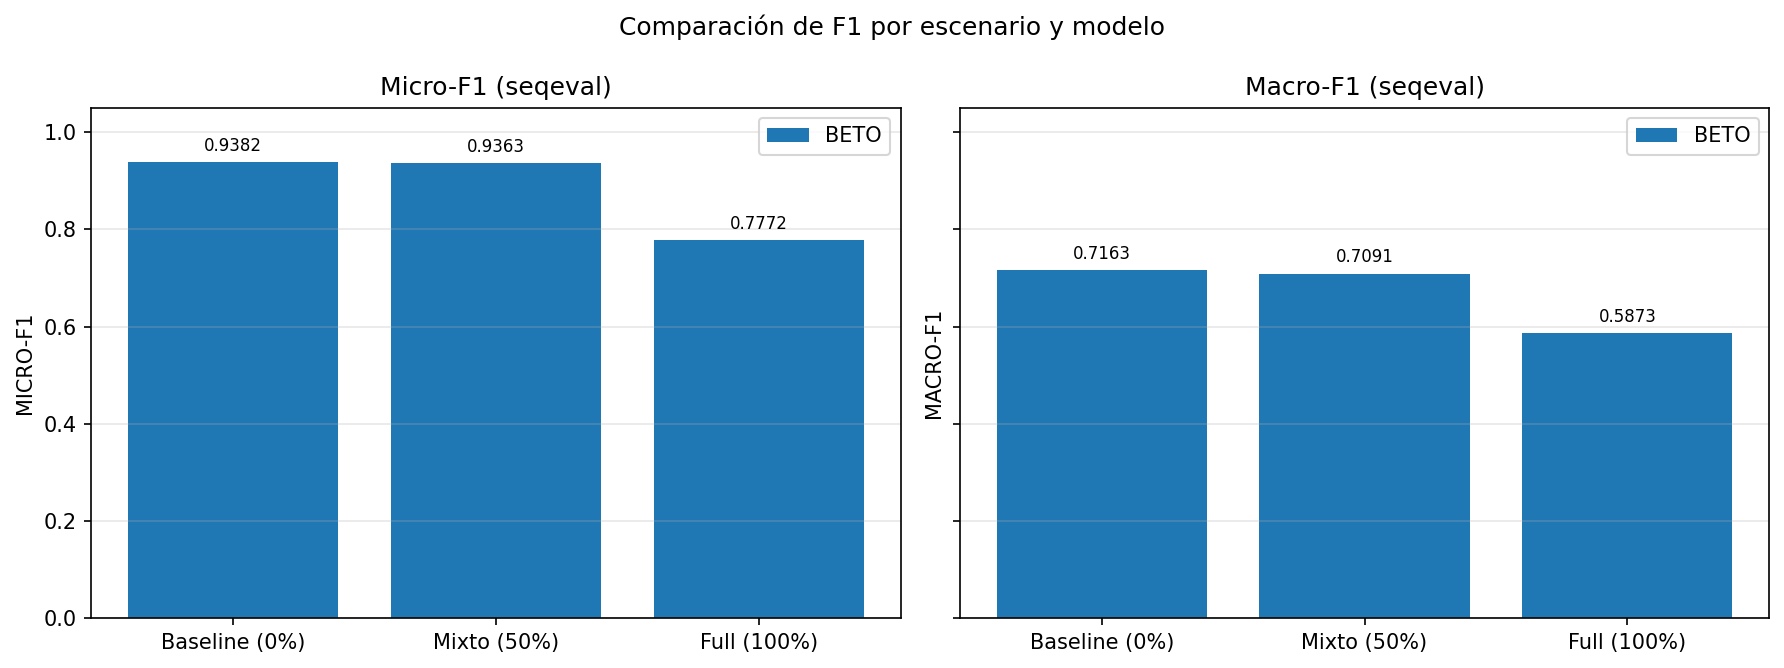

In [3]:
def ordered_present(values, preferred):
    present = set(values)
    return [v for v in preferred if v in present] + sorted(present - set(preferred))


def grouped_bars(ax, metric: str, title: str) -> None:
    scenarios = ordered_present(df["scenario"], SCENARIO_ORDER)
    models = ordered_present(df["model"], MODEL_ORDER)
    x = list(range(len(scenarios)))
    width = 0.8 / max(len(models), 1)
    for i, model in enumerate(models):
        vals = [
            df[(df["model"] == model) & (df["scenario"] == s)][metric].mean()
            for s in scenarios
        ]
        offset = (i - (len(models) - 1) / 2) * width
        bars = ax.bar([xi + offset for xi in x], vals, width, label=model)
        for bar, val in zip(bars, vals):
            if pd.notna(val):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    val + 0.015,
                    f"{val:.4f}",
                    ha="center",
                    va="bottom",
                    fontsize=8,
                )
    ax.set_xticks(x)
    ax.set_xticklabels(scenarios)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(metric.replace("_", "-").upper())
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
    ax.legend()


fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
grouped_bars(axes[0], "micro_f1", "Micro-F1 (seqeval)")
grouped_bars(axes[1], "macro_f1", "Macro-F1 (seqeval)")
fig.suptitle("Comparación de F1 por escenario y modelo")
fig.tight_layout()
fig.savefig(RESULTS_DIR / "05_f1_por_escenario.png", dpi=300, bbox_inches="tight")
plt.show()


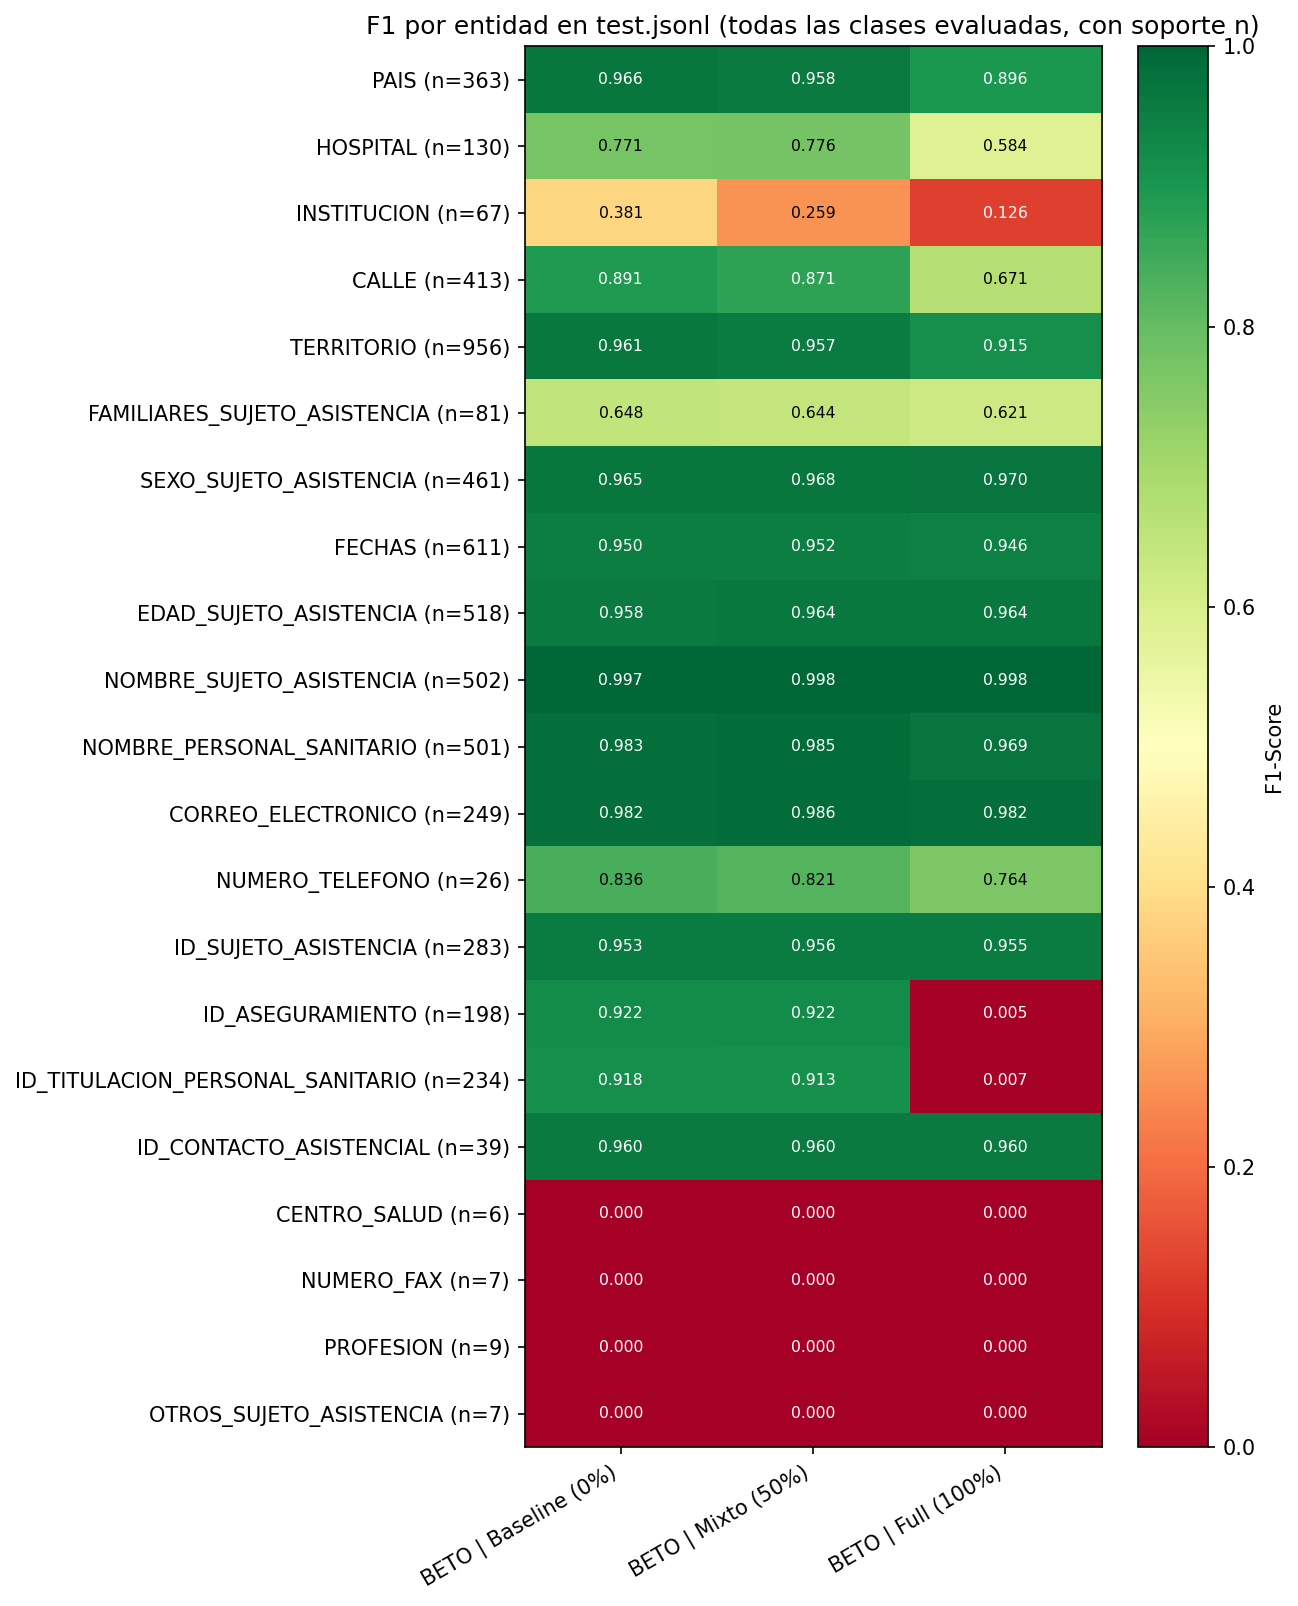

,Entidad,Soporte,BETO | Baseline (0%),BETO | Mixto (50%),BETO | Full (100%)
0,PAIS,363,0.9656,0.9576,0.8958
1,HOSPITAL,130,0.7708,0.7762,0.5841
2,INSTITUCION,67,0.3810,0.2586,0.1261
3,CALLE,413,0.8915,0.8715,0.6710
4,TERRITORIO,956,0.9612,0.9570,0.9146
5,FAMILIARES_SUJETO_ASISTENCIA,81,0.6480,0.6441,0.6211
6,SEXO_SUJETO_ASISTENCIA,461,0.9649,0.9680,0.9701
7,FECHAS,611,0.9495,0.9518,0.9463
8,EDAD_SUJETO_ASISTENCIA,518,0.9575,0.9638,0.9639
9,NOMBRE_SUJETO_ASISTENCIA,502,0.9970,0.9980,0.9980


In [4]:
FOCUS_LABELS = [
    "PAIS",
    "HOSPITAL",
    "INSTITUCION",
    "CALLE",
    "TERRITORIO",
    "FAMILIARES_SUJETO_ASISTENCIA",
    "SEXO_SUJETO_ASISTENCIA",
    "FECHAS",
    "EDAD_SUJETO_ASISTENCIA",
    "NOMBRE_SUJETO_ASISTENCIA",
    "NOMBRE_PERSONAL_SANITARIO",
    "CORREO_ELECTRONICO",
    "NUMERO_TELEFONO",
    "ID_SUJETO_ASISTENCIA",
    "ID_ASEGURAMIENTO",
    "ID_TITULACION_PERSONAL_SANITARIO",
    "ID_CONTACTO_ASISTENCIAL",
    "CENTRO_SALUD",
    "NUMERO_FAX",
    "PROFESION",
    "OTROS_SUJETO_ASISTENCIA",
]

per_entity_rows = []
for path in sorted(RESULTS_DIR.glob("*/04_per_entity.csv")):
    summary_path = path.parent / "04_eval_summary.json"
    if not summary_path.exists():
        continue
    s = json.loads(summary_path.read_text(encoding="utf-8"))
    e = pd.read_csv(path)
    e["run"] = path.parent.name
    e["model"] = normalize_model(s)
    e["scenario"] = normalize_scenario(s)
    per_entity_rows.append(e)

per_entity = pd.concat(per_entity_rows, ignore_index=True) if per_entity_rows else pd.DataFrame()
if per_entity.empty:
    print("No se encontraron 04_per_entity.csv")
else:
    per_entity["col"] = per_entity["model"].astype(str) + " | " + per_entity["scenario"].astype(str)
    col_order = [
        f"{m} | {sc}"
        for m in ordered_present(per_entity["model"], MODEL_ORDER)
        for sc in ordered_present(per_entity["scenario"], SCENARIO_ORDER)
        if f"{m} | {sc}" in set(per_entity["col"])
    ]
    row_order = [lbl for lbl in FOCUS_LABELS if lbl in set(per_entity["label"])] + sorted(
        set(per_entity["label"]) - set(FOCUS_LABELS)
    )

    pivot = (
        per_entity.pivot_table(index="label", columns="col", values="f1", aggfunc="mean", sort=False)
        .reindex(index=row_order, columns=col_order)
        .fillna(0.0)
    )
    support_map = per_entity.groupby("label")["support"].first().reindex(row_order).fillna(0).astype(int)

    fig, ax = plt.subplots(
        figsize=(max(8.5, 1.8 * pivot.shape[1]), 0.42 * pivot.shape[0] + 2.0)
    )
    im = ax.imshow(pivot.values, aspect="auto", vmin=0, vmax=1, cmap="RdYlGn")
    ax.set_xticks(range(pivot.shape[1]))
    ax.set_xticklabels(pivot.columns, rotation=30, ha="right")
    ax.set_yticks(range(pivot.shape[0]))
    ax.set_yticklabels([f"{lbl} (n={support_map[lbl]})" for lbl in pivot.index])
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.values[i, j]
            text_color = "white" if val < 0.25 or val > 0.85 else "black"
            ax.text(j, i, f"{val:.3f}", ha="center", va="center", fontsize=7.5, color=text_color)
    fig.colorbar(im, ax=ax, label="F1-Score")
    ax.set_title("F1 por entidad en test.jsonl (todas las clases evaluadas, con soporte n)")
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / "05_f1_entidades_clave.png", dpi=300, bbox_inches="tight")
    plt.show()

    entity_table = pivot.copy().round(4)
    entity_table.insert(0, "Soporte", support_map)
    entity_table = entity_table.reset_index().rename(columns={"label": "Entidad"})
    entity_table.columns.name = None
    display(entity_table)


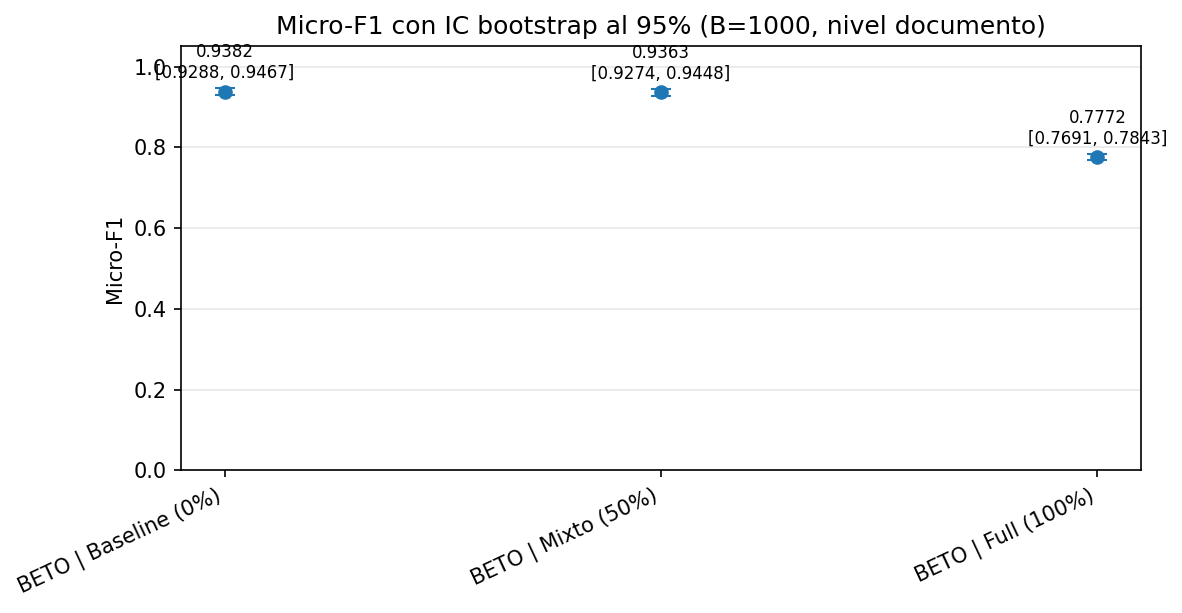

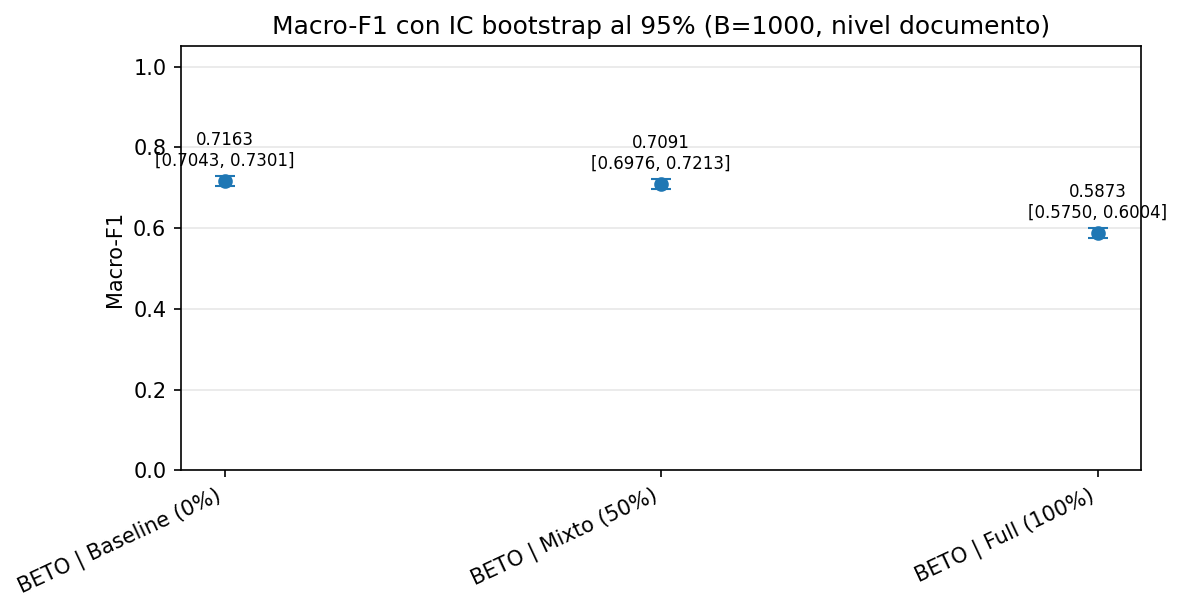

In [5]:
def plot_bootstrap_ci(df_runs: pd.DataFrame, metric_col: str, low_col: str, high_col: str, title: str, ylabel: str, out_name: str) -> None:
    boot = df_runs.dropna(subset=[low_col, high_col]).copy()
    if boot.empty:
        print(f"Sin intervalos bootstrap para {metric_col}. Ejecuta la Fase 4 con --bootstrap 1000.")
        return

    labels = boot["model"].astype(str) + " | " + boot["scenario"].astype(str)
    x = list(range(len(boot)))
    y = boot[metric_col].to_numpy(dtype=float)
    low = y - boot[low_col].to_numpy(dtype=float)
    high = boot[high_col].to_numpy(dtype=float) - y

    fig, ax = plt.subplots(figsize=(max(8, 1.5 * len(boot)), 4.2))
    ax.errorbar(x, y, yerr=[low, high], fmt="o", capsize=5, linewidth=1.5, markersize=6)
    for xi, yi, lo, hi in zip(x, y, boot[low_col], boot[high_col]):
        ax.text(xi, hi + 0.015, f"{yi:.4f}\n[{lo:.4f}, {hi:.4f}]", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=25, ha="right")
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / out_name, dpi=300, bbox_inches="tight")
    plt.show()


plot_bootstrap_ci(
    df,
    metric_col="micro_f1",
    low_col="boot_micro_low",
    high_col="boot_micro_high",
    title="Micro-F1 con IC bootstrap al 95% (B=1000, nivel documento)",
    ylabel="Micro-F1",
    out_name="05_bootstrap_micro_f1.png",
)

plot_bootstrap_ci(
    df,
    metric_col="macro_f1",
    low_col="boot_macro_low",
    high_col="boot_macro_high",
    title="Macro-F1 con IC bootstrap al 95% (B=1000, nivel documento)",
    ylabel="Macro-F1",
    out_name="05_bootstrap_macro_f1.png",
)


In [6]:
latex_resultados = thesis_table.to_latex(
    index=False,
    caption="Resultados globales en test.jsonl por modelo y escenario de aumentación (seqeval, nivel entidad, IC bootstrap 95\\%).",
    label="tab:resultados_ner",
    escape=True,
    float_format="%.4f".__mod__,
)
(RESULTS_DIR / "05_tabla_resultados.tex").write_text(latex_resultados, encoding="utf-8")
print("=== 05_tabla_resultados.tex ===")
print(latex_resultados)

table_micro_clean = table_micro.round(4).reset_index().rename(columns={"scenario": "Escenario"})
table_micro_clean.columns.name = None
latex_micro = table_micro_clean.to_latex(
    index=False,
    caption="Micro-F1 por escenario y modelo (seqeval, nivel entidad).",
    label="tab:micro_f1",
    escape=True,
    float_format="%.4f".__mod__,
)
(RESULTS_DIR / "05_tabla_micro_f1.tex").write_text(latex_micro, encoding="utf-8")

if not per_entity.empty:
    latex_entidades = entity_table.to_latex(
        index=False,
        caption="F1-Score por categoría de entidad en test.jsonl según escenario de entrenamiento.",
        label="tab:f1_por_entidad",
        escape=True,
        float_format="%.4f".__mod__,
    )
    (RESULTS_DIR / "05_tabla_por_entidad.tex").write_text(latex_entidades, encoding="utf-8")
    print("=== 05_tabla_por_entidad.tex ===")
    print(latex_entidades)


=== 05_tabla_resultados.tex ===
\begin{table}
\caption{Resultados globales en test.jsonl por modelo y escenario de aumentación (seqeval, nivel entidad, IC bootstrap 95\%).}
\label{tab:resultados_ner}
\begin{tabular}{llrlrlrrr}
\toprule
Modelo & Escenario & Micro-F1 & IC95 micro & Macro-F1 & IC95 macro & Weighted-F1 & Precision & Recall \\
\midrule
BETO & Baseline (0\%) & 0.9382 & [0.9288, 0.9467] & 0.7163 & [0.7043, 0.7301] & 0.9363 & 0.9310 & 0.9456 \\
BETO & Mixto (50\%) & 0.9363 & [0.9274, 0.9448] & 0.7091 & [0.6976, 0.7213] & 0.9337 & 0.9316 & 0.9410 \\
BETO & Full (100\%) & 0.7772 & [0.7691, 0.7843] & 0.5873 & [0.5750, 0.6004] & 0.8298 & 0.7218 & 0.8419 \\
\bottomrule
\end{tabular}
\end{table}

=== 05_tabla_por_entidad.tex ===
\begin{table}
\caption{F1-Score por categoría de entidad en test.jsonl según escenario de entrenamiento.}
\label{tab:f1_por_entidad}
\begin{tabular}{lrrrr}
\toprule
Entidad & Soporte & BETO | Baseline (0\%) & BETO | Mixto (50\%) & BETO | Full (100\%) \\
\mid

## Limitaciones metodológicas y experimentales

1. **Evaluación sobre `test.jsonl` original (SPACCC_MEDDOCAN de España) y ausencia de test clínico peruano:** El conjunto de prueba se mantuvo intacto respecto al corpus original para evitar *data leakage*. Por tanto, las métricas reportadas evalúan **retención de capacidad y robustez en español clínico peninsular** frente a la inyección de entidades peruanas en entrenamiento, pero **no miden directamente la adaptación en producción sobre textos clínicos peruanos reales** (lo cual requiere un *gold set* clínico peruano anotado manualmente).
2. **Entrenamiento con semilla única (`seed=42`):** Cada combinación fue entrenada con una única semilla aleatoria. No se reporta la varianza entre múltiples inicializaciones del clasificador ni entre distintos muestreos de aumentación.
3. **Alcance de los intervalos de confianza bootstrap (nivel documento):** Los intervalos al 95 % se calcularon mediante remuestreo con reemplazo de los 250 documentos del conjunto de prueba ($B=1000$). La superposición de intervalos entre `Baseline (0%)` ($[0.9288, 0.9467]$) y `Mixto (50%)` ($[0.9274, 0.9448]$) sugiere un rendimiento global comparable, pero **no constituye una prueba formal de equivalencia ni de no-inferioridad**; para contrastar diferencias pareadas se recomienda un test de permutación o *bootstrap* pareado sobre $\Delta \text{F1}$ documento a documento.
4. **Sensibilidad del Macro-F1 a clases raras con $\text{F1}=0$:** De las 21 etiquetas presentes en `test.jsonl`, cuatro clases de muy bajo soporte (`CENTRO_SALUD` $n=6$, `NUMERO_FAX` $n=7$, `OTROS_SUJETO_ASISTENCIA` $n=7$ y `PROFESION` $n=9$) obtienen $\text{F1}=0.0000$ en los tres escenarios. Como el Macro-F1 pondera por igual las 21 clases evaluadas, estas cuatro categorías reducen el promedio macro en ~19 puntos porcentuales respecto al Micro-F1. Adicionalmente, `ID_EMPLEO_PERSONAL_SANITARIO` no figura en `train` ni en `test` (solo 1 mención en `dev`).
5. **Domain Shift severo en el escenario `Full (100%)`:** La sustitución del 100 % de las entidades abiertas por patrones peruanos priva al modelo de ejemplos con estructura española durante el entrenamiento. Al evaluarse sobre `test.jsonl` (español), colapsan los identificadores con formato específico del corpus original: `ID_ASEGURAMIENTO` ($0.9223 \rightarrow 0.0052$) e `ID_TITULACION_PERSONAL_SANITARIO` ($0.9175 \rightarrow 0.0067$), además de caídas pronunciadas en `INSTITUCION` ($0.3810 \rightarrow 0.1261$), `HOSPITAL` ($0.7708 \rightarrow 0.5841$) y `CALLE` ($0.8915 \rightarrow 0.6710$).
6. **Comportamiento heterogéneo por entidad en `Mixto (50%)`:** Aunque el escenario Mixto conserva el Micro-F1 global ($0.9363$ frente a $0.9382$ del Baseline) y mantiene estables `HOSPITAL` ($0.7708 \rightarrow 0.7762$), `ID_ASEGURAMIENTO` ($0.9223$) e `ID_SUJETO_ASISTENCIA` ($0.9532 \rightarrow 0.9564$), no todas las entidades se comportan de forma uniforme: `INSTITUCION` desciende de $0.3810$ a $0.2586$ y `CALLE` pasa de $0.8915$ a $0.8715$.
7. **Cobertura parcial de arquitecturas:** Están completadas y verificadas las 3 corridas de `BETO` (`dccuchile/bert-base-spanish-wwm-cased`); quedan pendientes las 3 corridas de `XLM-RoBERTa` (`xlm-roberta-base`). El código de este notebook ya soporta múltiples modelos de forma automática en cuanto se depositen sus resultados en `results/`.


## Guía de lectura para la tesis

1. **Micro-F1** es la métrica primaria global: pondera cada mención por igual y refleja el desempeño agregado sobre las 5.661 entidades del conjunto de prueba.
2. **Macro-F1** refleja el comportamiento en la cola larga de categorías poco frecuentes; debe interpretarse junto con la columna `Soporte` de `05_tabla_por_entidad.tex`.
3. Al comparar **Baseline vs. Mixto vs. Full**, separa las **entidades cerradas no aumentadas** (`FECHAS`, `EDAD_SUJETO_ASISTENCIA`, `SEXO_SUJETO_ASISTENCIA`, que permanecen en $\text{F1} \approx 0.95\text{--}0.97$ en los tres escenarios) de las **entidades abiertas peruanizadas** (`ID_*`, `HOSPITAL`, `CALLE`, `INSTITUCION`, `TERRITORIO`, `PAIS`).
4. Para incorporar las tablas en LaTeX, utiliza `\input{results/05_tabla_resultados.tex}` y `\input{results/05_tabla_por_entidad.tex}` (requiere `\usepackage{booktabs}`).
